# Blocking out a Le Mans winner: the Ford GT40

In 1966, the Ford GT40 famously dethroned Ferrari at Le Mans -- a story big enough to get its own movie. This library ships a detailed 3d scan of one (`download_gt40`): 277,000 triangles of compound curves, glass, vents and panel gaps. Nothing like the smooth height field of [Badacsony](minecraft_mountain.ipynb) or the simple [Stanford bunny](solid_bunny.ipynb).

Let's see if `voxelize_T3_H8` holds up against something this complicated -- and then put the resulting voxels to actual engineering use by estimating the car's frontal area.

In [1]:
from sigmaepsilon.mesh.downloads import download_gt40

mesh = download_gt40(read=True)
leaf = mesh[5]
coords_T3 = mesh.coords()
topo_T3 = leaf.cd.topology().to_numpy()

print(f"{coords_T3.shape[0]} points, {topo_T3.shape[0]} triangles")
print(f"footprint: {coords_T3.max(axis=0) - coords_T3.min(axis=0)} (length, width, height)")

141204 points, 277030 triangles
footprint: [2506.51977539  990.90802002  542.25457764] (length, width, height)


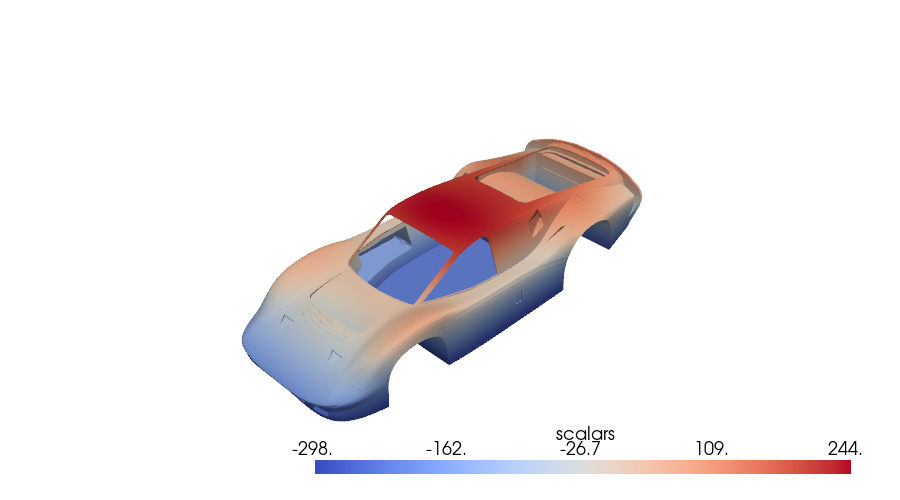

In [2]:
import pyvista as pv

pv_mesh = mesh.to_pv(multiblock=False, scalars=coords_T3[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(900, 500))
plotter.add_mesh(pv_mesh, cmap="coolwarm", show_edges=False)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Minecraft-ifying it anyway

`voxelize_T3_H8` doesn't care whether the surface is a height field, a rabbit, or a race car -- it just checks which voxels of a bounding-box grid are touched by the triangles. At a chunky resolution, the GT40 comes out unmistakably itself.

4476 blocks


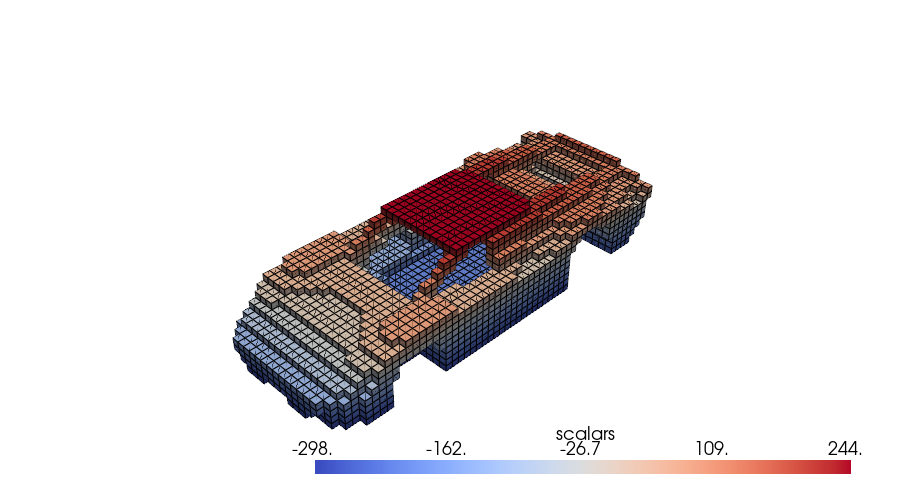

In [3]:
import numpy as np
from sigmaepsilon.mesh.voxelize import voxelize_T3_H8
from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import H8

frame = CartesianFrame(dim=3)


def voxelize_and_plot(shape, **plot_kwargs):
    coords_H8, topo_H8 = voxelize_T3_H8(coords_T3, topo_T3, shape=shape, k_max=10)
    pd = PointData(coords=coords_H8, frame=frame)
    cd = H8(topo=topo_H8, frames=frame)
    pv_obj = PolyData(pd, cd).to_pv(multiblock=False, scalars=coords_H8[:, 2])[0]
    plotter = pv.Plotter(**plot_kwargs)
    plotter.add_mesh(pv_obj, cmap="coolwarm", show_edges=True)
    plotter.camera_position = "iso"
    return plotter, topo_H8


plotter, topo_H8 = voxelize_and_plot((55, 20, 13), notebook=True, window_size=(900, 500))
print(f"{topo_H8.shape[0]} blocks")
plotter.show(jupyter_backend="static")

How low can the resolution go before it stops reading as a car? Let's compare a coarse and a very coarse grid side by side.

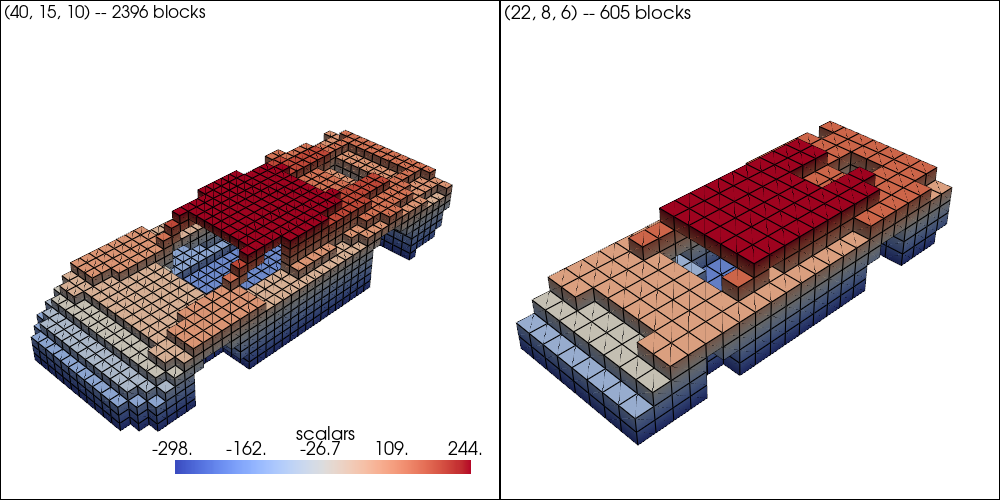

In [4]:
plotter = pv.Plotter(notebook=True, window_size=(1000, 500), shape=(1, 2))

for i, shape in enumerate([(40, 15, 10), (22, 8, 6)]):
    coords_H8, topo_H8 = voxelize_T3_H8(coords_T3, topo_T3, shape=shape, k_max=10)
    pd = PointData(coords=coords_H8, frame=frame)
    cd = H8(topo=topo_H8, frames=frame)
    pv_obj = PolyData(pd, cd).to_pv(multiblock=False, scalars=coords_H8[:, 2])[0]
    plotter.subplot(0, i)
    plotter.add_mesh(pv_obj, cmap="coolwarm", show_edges=True)
    plotter.add_text(f"{shape} -- {topo_H8.shape[0]} blocks", font_size=10)
    plotter.camera_position = "iso"

plotter.show(jupyter_backend="static")

## From voxels to an engineering number

Frontal area -- the silhouette of the car as seen head-on -- is one of the two numbers (together with the drag coefficient) that determine aerodynamic drag: $F_d = \tfrac{1}{2}\rho v^2 C_d A$. We don't need a CAD model or a wind tunnel to estimate it: the voxel shell already wraps the whole silhouette, so projecting it onto the width-height plane and counting occupied cells gets us there directly from the scan.

In [5]:
size = coords_T3.max(axis=0) - coords_T3.min(axis=0)
shift = coords_T3.min(axis=0)


def frontal_area(shape):
    coords_H8, topo_H8 = voxelize_T3_H8(coords_T3, topo_T3, shape=shape, k_max=10)
    centers = coords_H8[topo_H8].mean(axis=1)
    resolution = size / np.array(shape)
    iy = np.floor((centers[:, 1] - shift[1]) / resolution[1]).astype(int)
    iz = np.floor((centers[:, 2] - shift[2]) / resolution[2]).astype(int)
    silhouette = set(zip(iy, iz))
    return len(silhouette) * resolution[1] * resolution[2], topo_H8.shape[0]


for shape in [(40, 15, 10), (80, 30, 20), (150, 55, 35), (220, 80, 50)]:
    area, n_blocks = frontal_area(shape)
    print(f"{shape}: {n_blocks:>6} blocks, frontal area {area:,.0f} (data units squared)")

(40, 15, 10):   2396 blocks, frontal area 490,756 (data units squared)


(80, 30, 20):  10756 blocks, frontal area 469,263 (data units squared)


(150, 55, 35):  37605 blocks, frontal area 462,518 (data units squared)


(220, 80, 50):  81487 blocks, frontal area 458,203 (data units squared)


As the grid is refined, the estimate settles down -- the coarse grids systematically overestimate the silhouette because every occupied cell is counted whole, even if the surface only clips its corner. This is exactly the same convergence behaviour we saw for volume in the bunny notebook, just applied to a projected area instead.

## Beyond the gimmick

There was no special-casing for "car" anywhere in this notebook -- `voxelize_T3_H8` only ever looks at triangles and a bounding box, so it applies just as well to a 3d scan of a turbine blade, a 3d-printed part, or, evidently, a Le Mans winner. And once a complex surface is on a regular voxel grid, a whole family of questions -- silhouette area, packaging/clearance checks, simple flow blockage estimates -- reduce to counting cells.